# pandaICT basic scenario and use cases

This pages defines a very basic scenario and pandaICT use cases for that scenario, meant to serve as a reference for early development. 


## Scenario

### pandapower network

We'll be using the simple example from the pp tutorial as obtained by

In [5]:
import pandapower as pp

net = pp.networks.example_simple()

This net has 7 buses, one 110/20 kV trafo and one load, sgen and gen each:

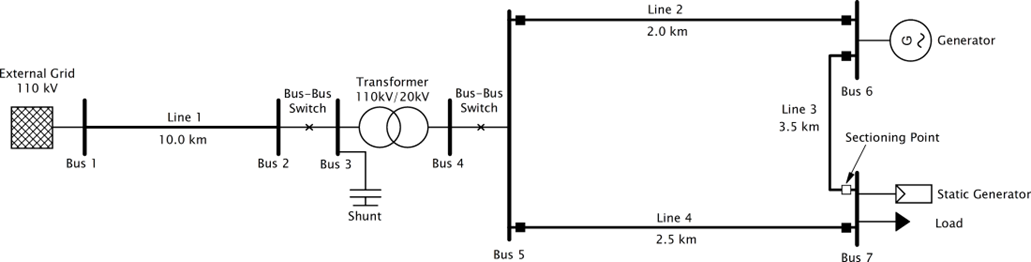

The trafo is equipped with a tap changer. The shunt is fixed. There are no timeseries included in the example. 

If we vary the infeed powers of the generators between 0..15 MVA / -12..12 MVar and consider both no-load and high-load (25 MVA) cases, we get some very extreme configuration with line loadings over 100%. E.g. line 2 is overloaded for multiple cases when Qsgen=-12 MVar, and line 1 is overloaded for multiple configurations when Pgen=12 MVA. Meanwhile, min/max voltage levels over all buses stay within 1 .. 1.05 p.U. for all cases. 

If the line lengths of line 2 and 4 are quadrupled, min/max voltages move between 0.935 .. 1.093 p.U. while line loadings look similar to before. When the line lengths stay original but line types are changed to the next weaker std type (NA2XS2Y 1x185 RM/25 12/20 kV), we still only get overloads if the absolute sgen reactive power exceeds 8. With the lines even weaker (NA2XS2Y 1x95 RM/25 12/20 kV), overloadings are possible with reactive power absolutes of 4 or less; notably, there are overloading cases with reactive powers of both generators being zero. Meanwhile voltages move between 0.996 .. 1.052 p.U. If line lengths are quadrupled in addition to that, line loadings would rise even more (up to 160%) and voltages would move between 0.91 .. 1.112 p.U.

To summarize, replacing the line types for lines 2 and 4 by NA2XS2Y 1x95 RM/25 12/20 kV while leaving line lengths unchanged would create an interesting use case for congestion management or a "Redispatch 2.0" scenario. A fixed cos phi could be set for both generators. To create a slightly more interesting scenario, it seems feasible to replace the gen by an sgen and treat the sgen at bus 6 as a wind farm, the one at bus 7 as PV plant. When cos phi for the generators is fixed to 0.98 and for the load to 0.95, line overloads may occur for certain load cases as soon as any of the generator's active powers exceeds 9 MVA. The trafo loading stays below 78% at all times. Voltages move between 0.99 .. 1.06 p.U.

The adapted network can be obtained by:

In [6]:
import pandapower as pp
net = pp.networks.example_simple()
pp.change_std_type(net,1,'NA2XS2Y 1x95 RM/25 12/20 kV','line')
pp.change_std_type(net,3,'NA2XS2Y 1x95 RM/25 12/20 kV','line')    
net.gen = net.gen.drop(0) # drop gen at bus 7        
pp.create_sgen(net, 5, p_mw=10, q_mvar=0, sn_mva=12, name="WPP", index=1) # create new 'PV' sgen at bus 7 
net.sgen.at[0,'name'] = 'PV' # make other sgen 'WPP' 
net.sgen.at[0,'q_mvar'] = 0 
net.load.at[0,'scaling'] = 1

Timeseries for WPP and PV sgens are generated using renewable.ninja for locations near Hambach/Pfalz. There are already two wind power plants at the location and there is sufficient space for PV. Maximal peak powers of 12 MVA for both generators are chosen for generation of hourly timeseries. The cosphi is set to 1. For the load, the standard load profile G0-M is taken from the SimBench dataset. This contains quarter-hourly normalized active and reactive powers. Only the values at the full hours are taken and multiplied by 4 to obtain an hourly MW / MVar timeseries. 
A pp timeseries simulation was carried out with the resulting network. The resulting line loadings exceed 100% for multiple times in the year and both the lines that were weakened compared to the original network. The bus voltages stay between 0.992 .. 1,037 p.U. The max trafo loading is 60%.

The network including timeseries is stored as "UC4_simple.json" in the test folder under the recode/pandaict git.

As a goal for the pandaICT model, an ICT infrastructure is added to the network according to the following graph. As for the ICTdevices, "CC" is the grid operator control center, "PQ" is a PQ meter, "TCC" is a trafo tap changer controller, and "PC" is an active power controller. 

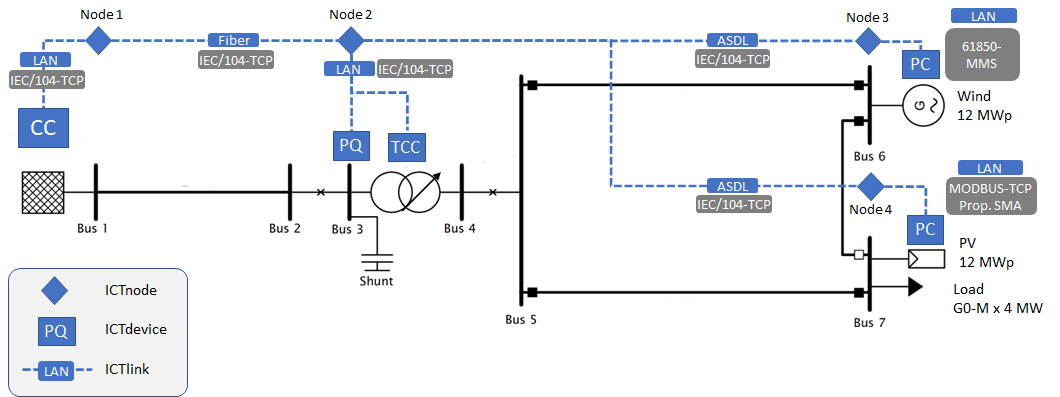
